**Libraries**

In [1]:
# Chapter 2, 3, 4, 5 — Required libraries

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import tiktoken

**GPT configuration**

In [2]:
# Chapter 4 — GPT-2 124M configuration
# Chapter 5 — Context length ko 256 rakha gaya hai

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

**Causal attention mask**

In [3]:
# Chapter 3 — Causal attention mask

class CausalAttention(nn.Module):

    def __init__(self, d_in, d_out, context_length,
                 dropout, qkv_bias=False):

        super().__init__()

        self.d_out = d_out

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):

        batch_size, num_tokens, d_in = x.shape

        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        attention_scores = queries @ keys.transpose(1, 2)

        attention_scores.masked_fill_(
            self.mask.bool()[:num_tokens, :num_tokens],
            -torch.inf
        )

        attention_weights = torch.softmax(
            attention_scores / keys.shape[-1]**0.5,
            dim=-1
        )

        attention_weights = self.dropout(attention_weights)

        context_vector = attention_weights @ values

        return context_vector

**Multi-head attention**

In [4]:
# Chapter 3 — Multi-head attention

class MultiHeadAttention(nn.Module):

    def __init__(self, d_in, d_out, context_length,
                 num_heads, dropout, qkv_bias=False):

        super().__init__()

        assert d_out % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)

        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):

        batch_size, num_tokens, d_in = x.shape

        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        keys = keys.view(
            batch_size, num_tokens, self.num_heads, self.head_dim
        ).transpose(1, 2)

        queries = queries.view(
            batch_size, num_tokens, self.num_heads, self.head_dim
        ).transpose(1, 2)

        values = values.view(
            batch_size, num_tokens, self.num_heads, self.head_dim
        ).transpose(1, 2)

        attention_scores = queries @ keys.transpose(2, 3)

        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        attention_scores.masked_fill_(
            mask_bool,
            -torch.inf
        )

        attention_weights = torch.softmax(
            attention_scores / self.head_dim**0.5,
            dim=-1
        )

        attention_weights = self.dropout(attention_weights)

        context_vector = attention_weights @ values

        context_vector = context_vector.transpose(1, 2)

        context_vector = context_vector.contiguous().view(
            batch_size, num_tokens, self.num_heads * self.head_dim
        )

        context_vector = self.out_proj(context_vector)

        return context_vector

**Layer normalization**

In [5]:
# Chapter 4 — Layer normalization

class LayerNorm(nn.Module):

    def __init__(self, emb_dim):

        super().__init__()

        self.eps = 1e-5

        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):

        mean = x.mean(dim=-1, keepdim=True)

        var = x.var(dim=-1, keepdim=True, unbiased=False)

        norm_x = (x - mean) / torch.sqrt(var + self.eps)

        return self.scale * norm_x + self.shift

**Feed-forward network**

In [6]:
# Chapter 4 — FeedForward network

class FeedForward(nn.Module):

    def __init__(self, cfg):

        super().__init__()

        self.layers = nn.Sequential(

            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),

            nn.GELU(),

            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])

        )

    def forward(self, x):

        return self.layers(x)

**Transformer block**

In [7]:
# Chapter 4 — Transformer block

class TransformerBlock(nn.Module):

    def __init__(self, cfg):

        super().__init__()

        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )

        self.ff = FeedForward(cfg)

        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])

        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):

        shortcut = x

        x = self.norm1(x)

        x = self.att(x)

        x = self.drop_shortcut(x)

        x = x + shortcut

        shortcut = x

        x = self.norm2(x)

        x = self.ff(x)

        x = self.drop_shortcut(x)

        x = x + shortcut

        return x

**GPT mode**

In [8]:
# Chapter 4 — Complete GPTModel architecture

class GPTModel(nn.Module):

    def __init__(self, cfg):

        super().__init__()

        self.tok_emb = nn.Embedding(
            cfg["vocab_size"],
            cfg["emb_dim"]
        )

        self.pos_emb = nn.Embedding(
            cfg["context_length"],
            cfg["emb_dim"]
        )

        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[
                TransformerBlock(cfg)
                for _ in range(cfg["n_layers"])
            ]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])

        self.out_head = nn.Linear(
            cfg["emb_dim"],
            cfg["vocab_size"],
            bias=False
        )

    def forward(self, in_idx):

        batch_size, seq_len = in_idx.shape

        tok_embeds = self.tok_emb(in_idx)

        pos_ids = torch.arange(
            seq_len,
            device=in_idx.device
        )

        pos_embeds = self.pos_emb(pos_ids)

        x = tok_embeds + pos_embeds

        x = self.drop_emb(x)

        x = self.trf_blocks(x)

        x = self.final_norm(x)

        logits = self.out_head(x)

        return logits

**Text generation function**

In [9]:
# Chapter 4 — generate_text_simple

def generate_text_simple(model, idx, max_new_tokens, context_size):

    for _ in range(max_new_tokens):

        idx_cond = idx[:, -context_size:]

        with torch.no_grad():

            logits = model(idx_cond)

        logits = logits[:, -1, :]

        idx_next = torch.argmax(
            logits,
            dim=-1,
            keepdim=True
        )

        idx = torch.cat(
            (idx, idx_next),
            dim=1
        )

    return idx

**Dataset class**

In [10]:
# Chapter 2 — GPTDatasetV1

class GPTDatasetV1(Dataset):

    def __init__(self, txt, tokenizer, max_length, stride):

        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt)

        for i in range(0, len(token_ids) - max_length, stride):

            input_chunk = token_ids[i:i + max_length]

            target_chunk = token_ids[i + 1:i + max_length + 1]

            self.input_ids.append(
                torch.tensor(input_chunk)
            )

            self.target_ids.append(
                torch.tensor(target_chunk)
            )

    def __len__(self):

        return len(self.input_ids)

    def __getitem__(self, idx):

        return self.input_ids[idx], self.target_ids[idx]

**DataLoader function**

In [11]:
# Chapter 2 — create_dataloader_v1

def create_dataloader_v1(
    txt,
    batch_size=4,
    max_length=256,
    stride=128,
    shuffle=True,
    drop_last=True
):

    tokenizer = tiktoken.get_encoding("gpt2")

    dataset = GPTDatasetV1(
        txt,
        tokenizer,
        max_length,
        stride
    )

    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last
    )

    return dataloader

**Model initialize**

In [12]:
# Chapter 5, Section 5.1.1 — Initialize GPT model

torch.manual_seed(123)

model = GPTModel(GPT_CONFIG_124M)

model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_value): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): 

**Text and Token IDs conversion**

In [13]:
# Chapter 2 — GPT-2 tokenizer

tokenizer = tiktoken.get_encoding("gpt2")


# Chapter 5, Section 5.1.1 — Text to Token IDs

def text_to_token_ids(text, tokenizer):

    encoded = tokenizer.encode(
        text,
        allowed_special={"<|endoftext|>"}
    )

    encoded_tensor = torch.tensor(encoded).unsqueeze(0)

    return encoded_tensor


# Chapter 5, Section 5.1.1 — Token IDs to Text

def token_ids_to_text(token_ids, tokenizer):

    flat = token_ids.squeeze(0)

    return tokenizer.decode(flat.tolist())

**Generate text**

In [14]:
# Chapter 5, Section 5.1.1 — Generate text

start_context = "Every effort moves you"

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


**Inputs and targets**

In [15]:
# Chapter 5, Section 5.1.2 — Input and target examples

inputs = torch.tensor([
    [16833, 3626, 6100],
    [40, 1107, 588]
])

targets = torch.tensor([
    [3626, 6100, 345],
    [588, 428, 11311]
])

**Logits and probabilities**

In [16]:
# Chapter 5, Section 5.1.2 — Calculate logits and probabilities

with torch.no_grad():

    logits = model(inputs)

    probas = torch.softmax(logits, dim=-1)

print("Logits shape:", logits.shape)
print("Probabilities shape:", probas.shape)

Logits shape: torch.Size([2, 3, 50257])
Probabilities shape: torch.Size([2, 3, 50257])


**Predicted token IDs**

In [17]:
# Chapter 5, Section 5.1.2 — Get predicted token IDs

token_ids = torch.argmax(
    probas,
    dim=-1,
    keepdim=True
)

print("Token IDs:\n", token_ids)

Token IDs:
 tensor([[[16657],
         [  339],
         [42826]],

        [[49906],
         [29669],
         [41751]]])


**Convert Targets and outputs into text**

In [18]:
# Chapter 5, Section 5.1.2 — Decode targets and model predictions

print(
    "Targets batch 1:",
    token_ids_to_text(targets[0], tokenizer)
)

print(
    "Outputs batch 1:",
    token_ids_to_text(token_ids[0].flatten(), tokenizer)
)

Targets batch 1:  effort moves you
Outputs batch 1:  Armed heNetflix


**Target token probabilities**

In [19]:
# Chapter 5, Section 5.1.2 — Extract probabilities of target tokens

text_idx = 0

target_probas_1 = probas[
    text_idx,
    [0, 1, 2],
    targets[text_idx]
]

print("Text 1:", target_probas_1)


text_idx = 1

target_probas_2 = probas[
    text_idx,
    [0, 1, 2],
    targets[text_idx]
]

print("Text 2:", target_probas_2)

Text 1: tensor([7.4537e-05, 3.1061e-05, 1.1563e-05])
Text 2: tensor([3.9834e-05, 1.6783e-05, 4.7559e-06])


**Log probabilities**

In [20]:
# Chapter 5, Section 5.1.2 — Calculate log probabilities

log_probas = torch.log(
    torch.cat((target_probas_1, target_probas_2))
)

print(log_probas)

tensor([ -9.5042, -10.3796, -11.3677, -10.1308, -10.9951, -12.2561])


**Average log probability**

In [21]:
# Chapter 5, Section 5.1.2 — Average log probability

avg_log_probas = torch.mean(log_probas)

print(avg_log_probas)

tensor(-10.7723)


**Negative average log probability**

In [22]:
# Chapter 5, Section 5.1.2 — Negative average log probability

neg_avg_log_probas = avg_log_probas * -1

print(neg_avg_log_probas)

tensor(10.7723)


**Cross entropy loss**

In [23]:
# Chapter 5, Section 5.1.2 — Check tensor shapes

print("Logits shape:", logits.shape)

print("Targets shape:", targets.shape)


# Flatten logits and targets

logits_flat = logits.flatten(0, 1)

targets_flat = targets.flatten()

print("Flattened logits:", logits_flat.shape)

print("Flattened targets:", targets_flat.shape)


# Calculate cross entropy loss

loss = torch.nn.functional.cross_entropy(
    logits_flat,
    targets_flat
)

print("Cross entropy loss:", loss)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])
Flattened logits: torch.Size([6, 50257])
Flattened targets: torch.Size([6])
Cross entropy loss: tensor(10.7723)


**Perplexity**

In [24]:
# Chapter 5, Section 5.1.2 — Calculate perplexity

perplexity = torch.exp(loss)

print("Perplexity:", perplexity)

Perplexity: tensor(47679.4570)


**Load The Verdict dataset**

In [25]:
# Chapter 2 — The Verdict dataset
# Chapter 5, Section 5.1.3 — Load text data

file_path = "the-verdict.txt"

with open(file_path, "r", encoding="utf-8") as file:

    text_data = file.read()


# Count characters and tokens

total_characters = len(text_data)

total_tokens = len(tokenizer.encode(text_data))

print("Characters:", total_characters)

print("Tokens:", total_tokens)

Characters: 20479
Tokens: 5145


**Training and validation split**

In [26]:
# Chapter 5, Section 5.1.3 — Split dataset

train_ratio = 0.90

split_idx = int(train_ratio * len(text_data))

train_data = text_data[:split_idx]

val_data = text_data[split_idx:]

print("Training characters:", len(train_data))

print("Validation characters:", len(val_data))

Training characters: 18431
Validation characters: 2048


**Create training DataLoader**

In [27]:
# Chapter 2 — create_dataloader_v1 function is defined in Cell 11
# Chapter 5, Section 5.1.3 — Training DataLoader

torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True
)

**Create validation DataLoader**

In [28]:
# Chapter 5, Section 5.1.3 — Validation DataLoader

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False
)

**Check DataLoader batches**

In [29]:
# Chapter 5, Section 5.1.3 — Inspect DataLoader

print("Train loader:")

for x, y in train_loader:

    print(x.shape, y.shape)


print("\nValidation loader:")

for x, y in val_loader:

    print(x.shape, y.shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])


**Calculate loss for one batch***

In [30]:
# Chapter 5, Section 5.1.3 — Calculate loss for a single batch

def calc_loss_batch(input_batch, target_batch, model, device):

    input_batch = input_batch.to(device)

    target_batch = target_batch.to(device)

    logits = model(input_batch)

    loss = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1),
        target_batch.flatten()
    )

    return loss

**Calculate loss for complete DataLoader**

In [31]:
# Chapter 5, Section 5.1.3 — Calculate loss over DataLoader

def calc_loss_loader(data_loader, model, device, num_batches=None):

    total_loss = 0.

    if num_batches is None:

        num_batches = len(data_loader)

    else:

        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):

        if i < num_batches:

            loss = calc_loss_batch(
                input_batch,
                target_batch,
                model,
                device
            )

            total_loss += loss.item()

        else:

            break

    return total_loss / num_batches

**Calculate initial training and validation loss**

In [32]:
# Chapter 5, Section 5.1.3 — Evaluate initial model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

train_loss = calc_loss_loader(
    train_loader,
    model,
    device
)

val_loss = calc_loss_loader(
    val_loader,
    model,
    device
)

print("Training loss:", train_loss)

print("Validation loss:", val_loss)

Training loss: 10.987581888834635
Validation loss: 10.98110580444336


**5.2**

**Model evaluation function**

In [33]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):

    model.eval()

    with torch.no_grad():

        train_loss = calc_loss_loader(
            train_loader, model, device, num_batches=eval_iter
        )

        val_loss = calc_loss_loader(
            val_loader, model, device, num_batches=eval_iter
        )

    model.train()

    return train_loss, val_loss

**Generate text during Training**

In [34]:
def generate_and_print_sample(model, tokenizer, device, start_context):

    model.eval()

    context_size = model.pos_emb.weight.shape[0]

    encoded = text_to_token_ids(start_context, tokenizer).to(device)

    with torch.no_grad():

        token_ids = generate_text_simple(
            model=model,
            idx=encoded,
            max_new_tokens=50,
            context_size=context_size
        )

    decoded_text = token_ids_to_text(token_ids, tokenizer)

    print(decoded_text.replace("\n", " "))

    model.train()

**Main training function**

In [35]:
def train_model_simple(
    model,
    train_loader,
    val_loader,
    optimizer,
    device,
    num_epochs,
    eval_freq,
    eval_iter,
    start_context
):

    train_losses, val_losses, track_tokens_seen = [], [], []

    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):

        model.train()

        for input_batch, target_batch in train_loader:

            optimizer.zero_grad()

            loss = calc_loss_batch(
                input_batch, target_batch, model, device
            )

            loss.backward()

            optimizer.step()

            tokens_seen += input_batch.numel()

            global_step += 1

            if global_step % eval_freq == 0:

                train_loss, val_loss = evaluate_model(
                    model,
                    train_loader,
                    val_loader,
                    device,
                    eval_iter
                )

                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)

                print(
                    f"Ep {epoch+1} (Step {global_step:06d}): "
                    f"Train loss {train_loss:.3f}, "
                    f"Val loss {val_loss:.3f}"
                )

                generate_and_print_sample(
                    model,
                    tokenizer,
                    device,
                    start_context
                )

    return train_losses, val_losses, track_tokens_seen

**AdamW optimizer setup**

In [36]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0004,
    weight_decay=0.1
)

**train model**

In [37]:
torch.manual_seed(123)

model = GPTModel(GPT_CONFIG_124M)

model.to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0004,
    weight_decay=0.1
)

num_epochs = 10

train_losses, val_losses, tokens_seen = train_model_simple(
    model,
    train_loader,
    val_loader,
    optimizer,
    device,
    num_epochs=num_epochs,
    eval_freq=5,
    eval_iter=1,
    start_context="Every effort moves you"
)

Ep 1 (Step 000000): Train loss 9.896, Val loss 9.933
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,, the the,,,,,,,,,,,,,,,,,,,
Ep 1 (Step 000005): Train loss 7.917, Val loss 8.339
Every effort moves you, the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the
Ep 2 (Step 000010): Train loss 6.847, Val loss 7.048
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,, the,,,,,,,,,,,,,,,,,,,,
Ep 2 (Step 000015): Train loss 5.997, Val loss 6.616
Every effort moves you, and, and,, and, and,,, and, and, and,, and,,,, and, and,, and,,,, and,, and,,, and, and,,, and, and
Ep 3 (Step 000020): Train loss 5.658, Val loss 6.598
Every effort moves you, and I had"                                             
Ep 3 (Step 000025): Train loss 5.367, Val loss 6.351
Every effort moves you his! Gisburn. Gisburn to the picture.   "I        "I. "I the of the--and it.  "I

**Training Loss Graph**

In [38]:
import matplotlib.pyplot as plt

def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):

    fig, ax1 = plt.subplots(figsize=(5, 3))

    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(
        epochs_seen,
        val_losses,
        linestyle="-.",
        label="Validation loss"
    )

    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")

    ax2 = ax1.twiny()

    ax2.plot(tokens_seen, train_losses, alpha=0)

    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()

    plt.show()

**Graph display**

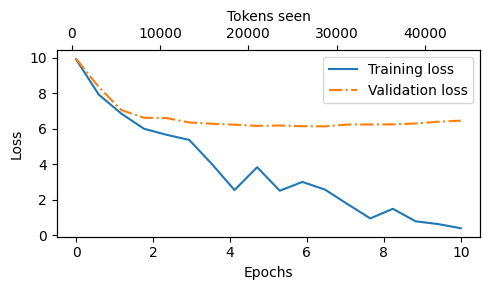

In [39]:
epochs_tensor = torch.linspace(
    0, num_epochs, len(train_losses)
)

plot_losses(
    epochs_tensor,
    tokens_seen,
    train_losses,
    val_losses
)

**5.3**

In [42]:
# Chapter 5.3: Initial setup

model.to("cpu")
model.eval()

import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


**Temperature Scaling**

In [43]:
vocab = {
    "closer": 0,
    "every": 1,
    "effort": 2,
    "forward": 3,
    "inches": 4,
    "moves": 5,
    "pizza": 6,
    "toward": 7,
    "you": 8
}

# Token ID ko dobara word mein convert karne ke liye
inverse_vocab = {v: k for k, v in vocab.items()}

next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

probas = torch.softmax(next_token_logits, dim=0)

next_token_id = torch.argmax(probas).item()

print("Selected word:", inverse_vocab[next_token_id])

Selected word: forward


**Multinomial sampling**

In [44]:
torch.manual_seed(123)

next_token_id = torch.multinomial(
    probas,
    num_samples=1
).item()

print("Sampled word:", inverse_vocab[next_token_id])

Sampled word: forward


**sampling repeat 1000 times**

In [45]:
def print_sampled_tokens(probas):

    torch.manual_seed(123)

    sample = [
        torch.multinomial(probas, num_samples=1).item()
        for i in range(1000)
    ]

    sampled_ids = torch.bincount(
        torch.tensor(sample),
        minlength=len(vocab)
    )

    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")



print_sampled_tokens(probas)

73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward
0 x you


**Temperature scaling function**

In [46]:
def softmax_with_temperature(logits, temperature):

    scaled_logits = logits / temperature

    return torch.softmax(scaled_logits, dim=0)


temperatures = [1, 0.1, 5]

scaled_probas = [
    softmax_with_temperature(next_token_logits, T)
    for T in temperatures
]

for T, prob in zip(temperatures, scaled_probas):

    print(f"\nTemperature: {T}")
    print(prob)


Temperature: 1
tensor([6.0907e-02, 1.6313e-03, 1.0019e-04, 5.7212e-01, 3.4190e-03, 1.3257e-04,
        1.0120e-04, 3.5758e-01, 4.0122e-03])

Temperature: 0.1
tensor([1.8530e-10, 3.5189e-26, 2.6890e-38, 9.9099e-01, 5.7569e-23, 4.4220e-37,
        2.9718e-38, 9.0133e-03, 2.8514e-22])

Temperature: 5
tensor([0.1546, 0.0750, 0.0429, 0.2421, 0.0869, 0.0454, 0.0430, 0.2203, 0.0898])


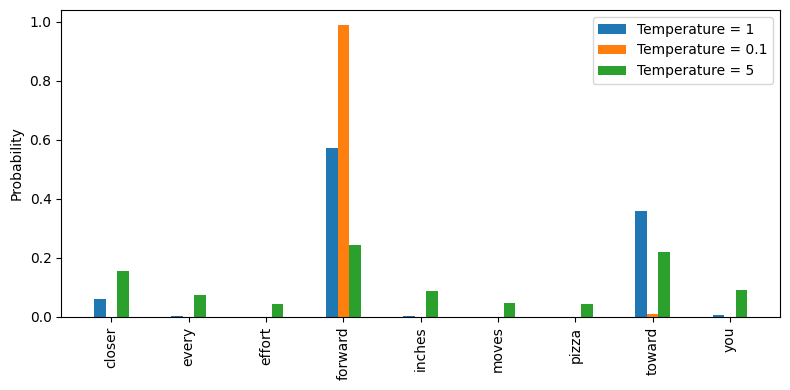

In [47]:
import matplotlib.pyplot as plt
import torch

x = torch.arange(len(vocab))

bar_width = 0.15

fig, ax = plt.subplots(figsize=(8, 4))

for i, T in enumerate(temperatures):

    ax.bar(
        x + i * bar_width,
        scaled_probas[i],
        bar_width,
        label=f"Temperature = {T}"
    )

ax.set_ylabel("Probability")

ax.set_xticks(x + bar_width)

ax.set_xticklabels(
    vocab.keys(),
    rotation=90
)

ax.legend()

plt.tight_layout()
plt.show()

**Top-k Sampling**

In [48]:
top_k = 3

top_logits, top_pos = torch.topk(
    next_token_logits,
    top_k
)

print("Top logits:", top_logits)
print("Top positions:", top_pos)


new_logits = torch.where(
    condition=next_token_logits < top_logits[-1],
    input=torch.tensor(float("-inf")),
    other=next_token_logits
)

print(new_logits)

topk_probas = torch.softmax(
    new_logits,
    dim=0
)

print(topk_probas)

Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions: tensor([3, 7, 0])
tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])
tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


**New generate() function**

In [49]:
def generate(
    model,
    idx,
    max_new_tokens,
    context_size,
    temperature=0.0,
    top_k=None
):

    # Har iteration mein aik naya token generate hoga
    for _ in range(max_new_tokens):

        # Model ke context size ke mutabiq input restrict karna
        idx_cond = idx[:, -context_size:]

        # Model se logits calculate karna
        with torch.no_grad():
            logits = model(idx_cond)

        # Sirf last token ke logits lena
        logits = logits[:, -1, :]

        # Top-k sampling
        if top_k is not None:

            top_logits, _ = torch.topk(logits, top_k)

            min_val = top_logits[:, -1]

            logits = torch.where(
                logits < min_val,
                torch.tensor(float("-inf")).to(logits.device),
                logits
            )

        # Temperature scaling + probabilistic sampling
        if temperature > 0.0:

            logits = logits / temperature

            probs = torch.softmax(logits, dim=-1)

            idx_next = torch.multinomial(
                probs,
                num_samples=1
            )

        # Greedy decoding
        else:

            idx_next = torch.argmax(
                logits,
                dim=-1,
                keepdim=True
            )

        # Naya token purani sequence ke sath add karna
        idx = torch.cat(
            (idx, idx_next),
            dim=1
        )

    return idx

In [50]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=15,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=25,
    temperature=1.4
)

print(
    "Output text:\n",
    token_ids_to_text(token_ids, tokenizer)
)

Output text:
 Every effort moves you stand to work on surprise, a one of us had gone with random-


In [51]:
settings = [
    {"temperature": 0.2, "top_k": 5},
    {"temperature": 0.7, "top_k": 10},
    {"temperature": 1.0, "top_k": 25},
    {"temperature": 1.4, "top_k": 25},
    {"temperature": 1.4, "top_k": 50},
]

for setting in settings:

    torch.manual_seed(123)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids("Every effort moves you", tokenizer),
        max_new_tokens=20,
        context_size=GPT_CONFIG_124M["context_length"],
        temperature=setting["temperature"],
        top_k=setting["top_k"]
    )

    print("\nSettings:", setting)

    print(token_ids_to_text(token_ids, tokenizer))


Settings: {'temperature': 0.2, 'top_k': 5}
Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an

Settings: {'temperature': 0.7, 'top_k': 10}
Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an

Settings: {'temperature': 1.0, 'top_k': 25}
Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an

Settings: {'temperature': 1.4, 'top_k': 25}
Every effort moves you stand to work on surprise, a one of us had gone with random-dication: "Yes

Settings: {'temperature': 1.4, 'top_k': 50}
Every effort moves you not to work on surprise, a picture to face watching me by his knees. Professional: " yourself


In [52]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"],
    temperature=0,
    top_k=25
)

print(
    "Deterministic output:\n",
    token_ids_to_text(token_ids, tokenizer)
)

Deterministic output:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


In [53]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict()
    },
    "model_and_optimizer.pth"
)

In [54]:
checkpoint = torch.load(
    "model_and_optimizer.pth",
    map_location="cpu",
    weights_only=True
)

In [55]:
model = GPTModel(GPT_CONFIG_124M)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

<All keys matched successfully>

In [56]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.1
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

model.train()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_value): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): 

Training ko 1 epoch

In [57]:
# Model ko training ke liye device par bhejna
model.to(device)

# 1 additional epoch train karna
train_losses, val_losses, tokens_seen = train_model_simple(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    device=device,
    num_epochs=1,
    eval_freq=5,
    eval_iter=1,
    start_context="Every effort moves you"
)

Ep 1 (Step 000000): Train loss 0.292, Val loss 6.564
Every effort moves you?"  "Yes--quite insensible to the irony. She wanted him vindicated--and by me!"  He laughed again, and threw back his head to look up at the sketch of the donkey. "There were days when I
Ep 1 (Step 000005): Train loss 0.220, Val loss 6.576
Every effort moves you?"  "Yes--quite insensible to the irony. She wanted him vindicated--and by me!"  He laughed again, and threw back his head to look up at the sketch of the donkey. "There were days when I
